# Landsat 8/9: reflective and thermal bands on a common grid

Landsat 8 and 9 carry two instruments: the Operational Land Imager (OLI, 9 reflective bands at
30 m, 15 m for the panchromatic band) and the Thermal Infrared Sensor (TIRS, 2 bands at 100 m,
delivered resampled at 30 m in the Collection 2 products). GRSdriver loads them together on one
grid: TOA reflectance for the OLI bands and brightness temperature for the TIRS bands.

**You will learn to**

- load a Landsat Collection 2 Level-1 product with its thermal bands,
- choose a resolution and a region of interest,
- plot the reflectance and the brightness temperature.

**Data**: the Landsat 9 product of path/row 196/030 (Provence, France) of 2022-11-20, downloaded
from [USGS EarthExplorer](https://earthexplorer.usgs.gov) (Landsat Collection 2 Level-1). The
same area was imaged by Sentinel-2 that day (see the [subsetting tutorial](GRSdriver_subsetting.ipynb)).

In [1]:
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from shapely.geometry import box

import GRSdriver
from GRSdriver import LandsatDriver, driver_landsat_col2

print('GRSdriver', GRSdriver.__version__)

GRSdriver 2.0.0


In [2]:
def utm_projection(crs):
    """Cartopy UTM projection of a product CRS (EPSG 326xx: north, 327xx: south)."""
    epsg = crs.to_epsg()
    return ccrs.UTM(epsg % 100, southern_hemisphere=epsg // 100 == 327)

## Bands

The bands are indexed from 0 to 10; `Landsat band` is the band number of the product files
(`*_B<n>.TIF`):

In [3]:
driver_landsat_col2.INFO

bandId,0,1,2,3,4,5,6,7,8,9,10
ESA,B01,B02,B03,B08,B04,B05,B09,B06,B07,B08,B09
name,CA,BLUE,GREEN,PAN,RED,NIR,SWIR_CIRRUS,SWIR_1,SWIR_2,TIR_1,TIR_2
Landsat band,1,2,3,8,4,5,9,6,7,10,11
Wavelength (nm),443,490,560,590,665,865,1370,1610,2190,11000,12000
Band width (nm),25,60,60,173,33,28,21,95,287,590,1010
Resolution (m),30,30,30,15,30,30,30,30,30,100,100


## Load a region at 100 m

The native resolution of TIRS is 100 m: loading all the bands at 100 m avoids interpolating the
thermal bands (the OLI bands are averaged). The region covers Marseille and the Étang de Berre:

In [4]:
image = '/data/satellite/landsat/LC09_L1TP_196030_20221120_20230321_02_T1'

aoi = gpd.GeoSeries([box(4.93, 43.30, 5.33, 43.64)], crs=4326)   # lon/lat bounds

l1 = LandsatDriver(image,
                   band_idx=[1, 2, 4, 5, 7, 8, 9, 10],   # BLUE, GREEN, RED, NIR, SWIR_1, SWIR_2, TIR_1, TIR_2
                   subset=aoi,
                   resolution=100)
l1.load_product()
prod = l1.prod
prod

<xarray.Dataset> Size: 8MB
Dimensions:      (x: 335, y: 387, wl: 8, wl_hr: 2951)
Coordinates:
  * x            (x) float64 3kB 6.556e+05 6.557e+05 ... 6.889e+05 6.89e+05
  * y            (y) float64 3kB 4.835e+06 4.834e+06 ... 4.796e+06 4.796e+06
  * wl           (wl) float64 64B 490.0 560.0 665.0 ... 2.19e+03 1.1e+04 1.2e+04
  * wl_hr        (wl_hr) float64 24kB 400.0 401.0 402.0 ... 1.35e+04 1.35e+04
    spatial_ref  int64 8B 0
    time         datetime64[ns] 8B 2022-11-20T10:24:21
Data variables:
    bands        (wl, y, x) float32 4MB 0.1357 0.1342 0.134 ... 288.3 288.4
    SRF          (wl, wl_hr) float64 189kB ...
    wl_true      (wl) float64 64B 482.3 560.9 654.3 ... 1.084e+04 1.203e+04
    sza          (y, x) float64 1MB 64.94 64.93 64.93 ... 64.51 64.51 64.51
    vza          (y, x) float64 1MB 0.67 0.66 0.65 0.645 ... 3.17 3.177 3.184
    raa          (y, x) float64 1MB 84.75 85.06 85.38 ... 254.4 254.3 254.3
    flags_l1     (y, x) uint32 519kB 21824 21824 21824 ... 21952 21952 21952
Attributes: (12/16)
    long_name:              BLUE GREEN RED NIR SWIR_1 SWIR_2 TIR_1 TIR_2
    constellation:          Landsat-9
    constellation_id:       L9
    product_path:           /data/satellite/landsat/LC09_L1TP_196030_20221120...
    product_name:           LC09_L1TP_196030_20221120_20230321_02_T1
    instrument:             OLI-TIRS
    ...                     ...
    radiometry:             reflectance and brightness temperature
    cloud_cover:            0.2
    wl_to_process:          [ 443  490  560  590  665  865 1610 2190]
    satellite:              Landsat-9
    solar_irradiance:       NA
    solar_irradiance_unit:  W/m²/µm

The `bands` variable holds:

- for the OLI bands (wavelength <= 3000 nm): the TOA reflectance, divided by the cosine of the
  solar zenith angle;
- for the TIRS bands: the brightness temperature (K), from the TOA radiance and the thermal
  constants of the metadata.

`flags_l1` is the quality bitmask of the product (`QA_PIXEL`, see the [CAMS tutorial](GRSdriver_landsat9_L1_CAMS.ipynb)).

In [5]:
for key in ['satellite', 'tile', 'acquisition_date', 'radiometry', 'cloud_cover']:
    print(f'{key:18s}: {prod.attrs[key]}')

satellite         : Landsat-9
tile              : 196030
acquisition_date  : 2022-11-20 10:24:21
radiometry        : reflectance and brightness temperature
cloud_cover       : 0.2


## Spectral responses of the thermal bands

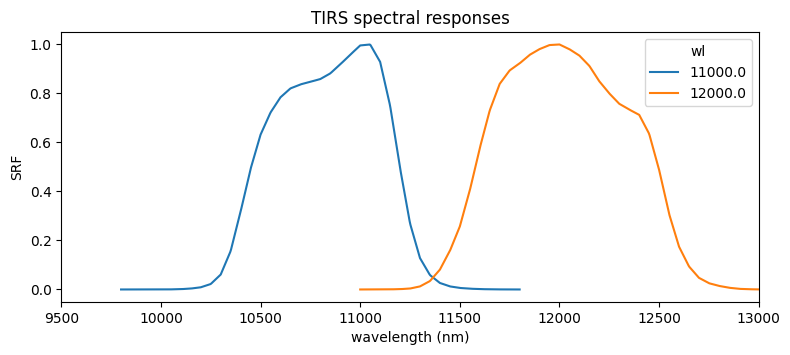

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.5))
prod.SRF.sel(wl=[11000, 12000]).plot(x='wl_hr', hue='wl', ax=ax)
ax.set_xlim(9500, 13000)
ax.set_xlabel('wavelength (nm)')
ax.set_title('TIRS spectral responses')
plt.show()

## Reflectance and brightness temperature

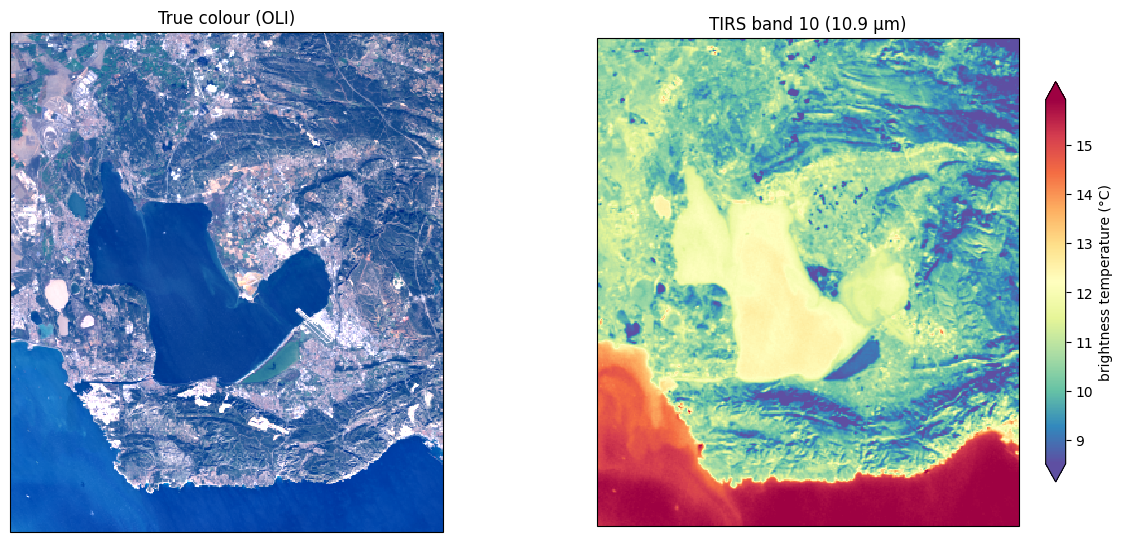

In [7]:
proj = utm_projection(prod.rio.crs)

fig, axs = plt.subplots(1, 2, figsize=(15, 6.5), subplot_kw={'projection': proj})
(prod.bands.sel(wl=[665, 560, 490]) ** 0.5).plot.imshow(ax=axs[0], rgb='wl', robust=True, transform=proj)
axs[0].set_title('True colour (OLI)')
(prod.bands.sel(wl=11000) - 273.15).plot.imshow(ax=axs[1], cmap='Spectral_r', robust=True, transform=proj,
                                                 cbar_kwargs={'label': 'brightness temperature (°C)', 'shrink': 0.8})
axs[1].set_title('TIRS band 10 (10.9 µm)')
plt.show()

In November, the open sea is warmer than the land, and the lagoon, shallower, is in between. The
difference between the two thermal bands ("split window") depends on the atmospheric water
vapour, which makes it useful to correct the surface temperature for the atmosphere, and on the
surface emissivity, which differs between water and land, as seen here:

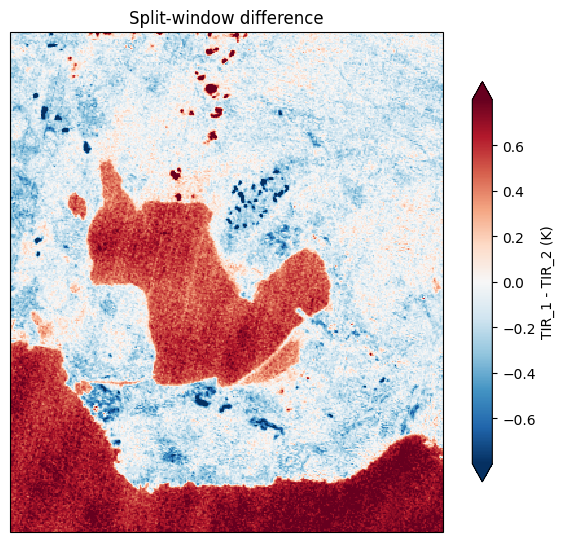

In [8]:
split_window = (prod.bands.sel(wl=11000) - prod.bands.sel(wl=12000)).rename('TIR_1 - TIR_2 (K)')
fig = plt.figure(figsize=(7.5, 6.5))
ax = plt.axes(projection=proj)
split_window.plot.imshow(ax=ax, cmap='RdBu_r', robust=True, transform=proj, cbar_kwargs={'shrink': 0.8})
ax.set_title('Split-window difference')
plt.show()

## Next steps

- [Landsat and CAMS](GRSdriver_landsat9_L1_CAMS.ipynb): quality flags and atmospheric auxiliary data for the same scene.
- The same driver loads Landsat 8 products.